# Model comparison

This notebook compares a simple majority-class baseline with the selected logistic-regression and LightGBM models. The chronological validation partition is used for comparison; the final test partition remains untouched until Milestone 4.

In [16]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from baselines import MajorityClassClassifier
from boosted_preprocessing import make_boosted_tree_preprocessor, prepare_boosted_tree_features
from model_data import RAW_MODEL_COLUMNS, prepare_model_data
from model_evaluation import macro_f1_test
from models import make_multinomial_logistic_regression
from prep_job import add_split_time, add_target, chronological_split, load_monthly_data, preprocess_partitions

## Prepare leakage-safe chronological partitions

The existing preprocessing functions create the target and chronological train/validation/test partitions. The linear preprocessor is fitted on training data only. The boosted preprocessor follows the same rule and keeps categorical features without one-hot encoding.

In [17]:
linear_data = prepare_model_data(PROJECT_ROOT / "data")

raw_data = load_monthly_data(PROJECT_ROOT / "data", RAW_MODEL_COLUMNS)
labelled_data = add_target(raw_data)
split_data = chronological_split(add_split_time(labelled_data))
processed_data = preprocess_partitions(split_data)

train_features, y_train_boosted = prepare_boosted_tree_features(processed_data["train"])
validation_features, y_validation_boosted = prepare_boosted_tree_features(processed_data["validation"])
test_features, y_test_boosted = prepare_boosted_tree_features(processed_data["test"])
boosted_preprocessor = make_boosted_tree_preprocessor()
X_train_boosted = boosted_preprocessor.fit_transform(train_features)
X_validation_boosted = boosted_preprocessor.transform(validation_features)
X_test_boosted = boosted_preprocessor.transform(test_features)

target_names = sorted(y_train_boosted.unique())
target_to_id = {name: index for index, name in enumerate(target_names)}
y_validation_boosted_labels = y_validation_boosted.copy()
y_train_boosted = y_train_boosted.map(target_to_id)
y_validation_boosted = y_validation_boosted.map(target_to_id)

pd.DataFrame({
    "partition": ["train", "validation", "test"],
    "rows": [len(linear_data.y_train), len(linear_data.y_validation), len(linear_data.y_test)],
    "linear_features": [linear_data.X_train.shape[1], linear_data.X_validation.shape[1], linear_data.X_test.shape[1]],
    "boosted_features": [X_train_boosted.shape[1], X_validation_boosted.shape[1], X_test_boosted.shape[1]],
})

,partition,rows,linear_features,boosted_features
0,train,9864275,4758,8
1,validation,2120356,4758,8
2,test,2126112,4758,8


## Train the three comparison models

The selected settings come from `model_tuning.ipynb`: logistic regression uses `C=0.01`; LightGBM uses 600 trees, 31 leaves, and learning rate 0.05. Macro-F1 is the primary metric because it gives equal importance to every delay class.

In [7]:
majority_model = MajorityClassClassifier()
logistic_model = make_multinomial_logistic_regression(C=0.01, max_iter=100)
lightgbm_model = LGBMClassifier(
    objective="multiclass",
    num_class=len(target_names),
    n_estimators=600,
    num_leaves=31,
    learning_rate=0.05,
    class_weight="balanced",
    device_type="cpu",
    verbosity=-1,
    random_state=42,
)

majority_model.fit(linear_data.X_train, linear_data.y_train)
logistic_model.fit(linear_data.X_train, linear_data.y_train)
categorical_columns = [
    column for column in X_train_boosted.columns
    if str(X_train_boosted[column].dtype) == "category"
]
lightgbm_model.fit(
    X_train_boosted,
    y_train_boosted,
    categorical_feature=categorical_columns,
)

models = {
    "majority_baseline": majority_model,
    "logistic_regression": logistic_model,
    "lightgbm": lightgbm_model,
}
predictions = {
    "majority_baseline": majority_model.predict(linear_data.X_validation),
    "logistic_regression": logistic_model.predict(linear_data.X_validation),
    "lightgbm": np.asarray(target_names)[lightgbm_model.predict(X_validation_boosted).astype(int)],
}

comparison = pd.DataFrame([
    macro_f1_test(
        models[name],
        linear_data.X_validation,
        linear_data.y_validation,
        model_name=name,
        predictions=predictions[name],
    )
    for name in models
]).sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True)
comparison

,model,n_test,macro_f1,accuracy
0,lightgbm,2120356,0.326504,0.394425
1,logistic_regression,2120356,0.309290,0.375253
2,majority_baseline,2120356,0.121340,0.435441


## Per-class validation performance

Macro-F1 can hide which delay classes are difficult. The classification reports below show precision, recall, and F1 for every class.

In [14]:
per_class_reports = {}
for name, predicted in predictions.items():
    per_class_reports[name] = pd.DataFrame(
        classification_report(
            linear_data.y_validation,
            predicted,
            labels=target_names,
            output_dict=True,
            zero_division=0,
        )
    ).T

all_per_class_reports = pd.concat(per_class_reports, names=["model", "class"])
all_per_class_reports

precision    recall  f1-score  \
model               class                                                
majority_baseline   delayed               0.000000  0.000000  0.000000   
                    late                  0.000000  0.000000  0.000000   
                    on_time               0.435441  1.000000  0.606700   
                    severe_or_cancelled   0.000000  0.000000  0.000000   
                    slight_delay          0.000000  0.000000  0.000000   
                    accuracy              0.435441  0.435441  0.435441   
                    macro avg             0.087088  0.200000  0.121340   
                    weighted avg          0.189608  0.435441  0.264182   
logistic_regression delayed               0.201084  0.231505  0.215225   
                    late                  0.334574  0.219988  0.265443   
                    on_time               0.626145  0.523076  0.569988   
                    severe_or_cancelled   0.180555  0.458102  0.259020   
                    slight_delay          0.230186  0.243745  0.236772   
                    accuracy              0.375253  0.375253  0.375253   
                    macro avg             0.314509  0.335283  0.309290   
                    weighted avg          0.417451  0.375253  0.387117   
lightgbm            delayed               0.218358  0.266290  0.239954   
                    late                  0.345049  0.220333  0.268936   
                    on_time               0.654481  0.548016  0.596536   
                    severe_or_cancelled   0.192456  0.444885  0.268681   
                    slight_delay          0.243046  0.275850  0.258411   
                    accuracy              0.394425  0.394425  0.394425   
                    macro avg             0.330678  0.351075  0.326504   
                    weighted avg          0.436982  0.394425  0.406521   

                                              support  
model               class                              
majority_baseline   delayed              2.430920e+05  
                    late                 4.459290e+05  
                    on_time              9.232890e+05  
                    severe_or_cancelled  1.609990e+05  
                    slight_delay         3.470470e+05  
                    accuracy             4.354406e-01  
                    macro avg            2.120356e+06  
                    weighted avg         2.120356e+06  
logistic_regression delayed              2.430920e+05  
                    late                 4.459290e+05  
                    on_time              9.232890e+05  
                    severe_or_cancelled  1.609990e+05  
                    slight_delay         3.470470e+05  
                    accuracy             3.752535e-01  
                    macro avg            2.120356e+06  
                    weighted avg         2.120356e+06  
lightgbm            delayed              2.430920e+05  
                    late                 4.459290e+05  
                    on_time              9.232890e+05  
                    severe_or_cancelled  1.609990e+05  
                    slight_delay         3.470470e+05  
                    accuracy             3.944253e-01  
                    macro avg            2.120356e+06  
                    weighted avg         2.120356e+06

## Confusion matrices

The confusion matrices show whether errors are concentrated between neighbouring delay categories or in a particular minority class.

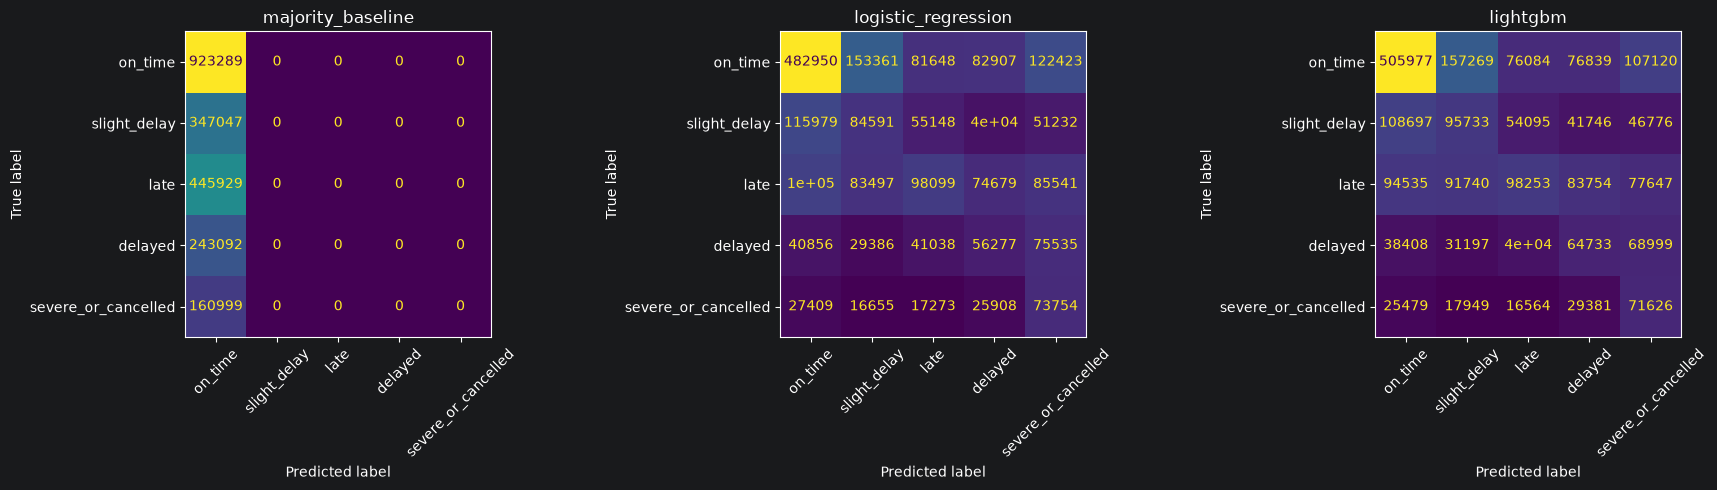

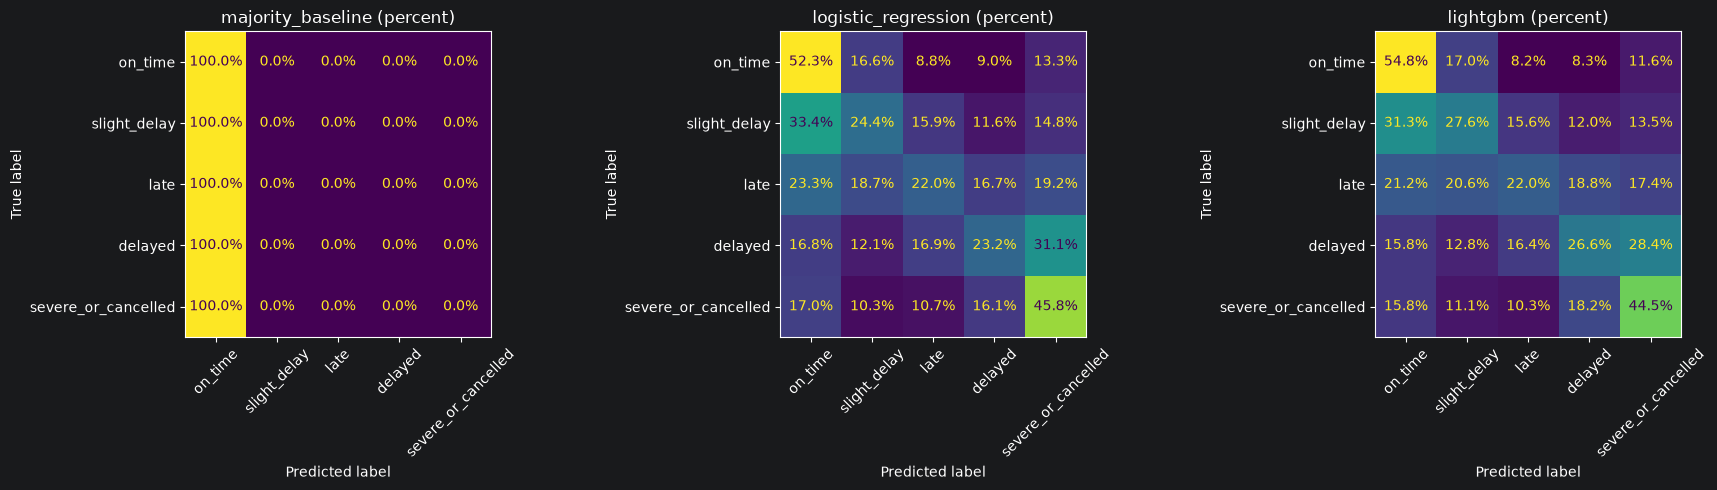

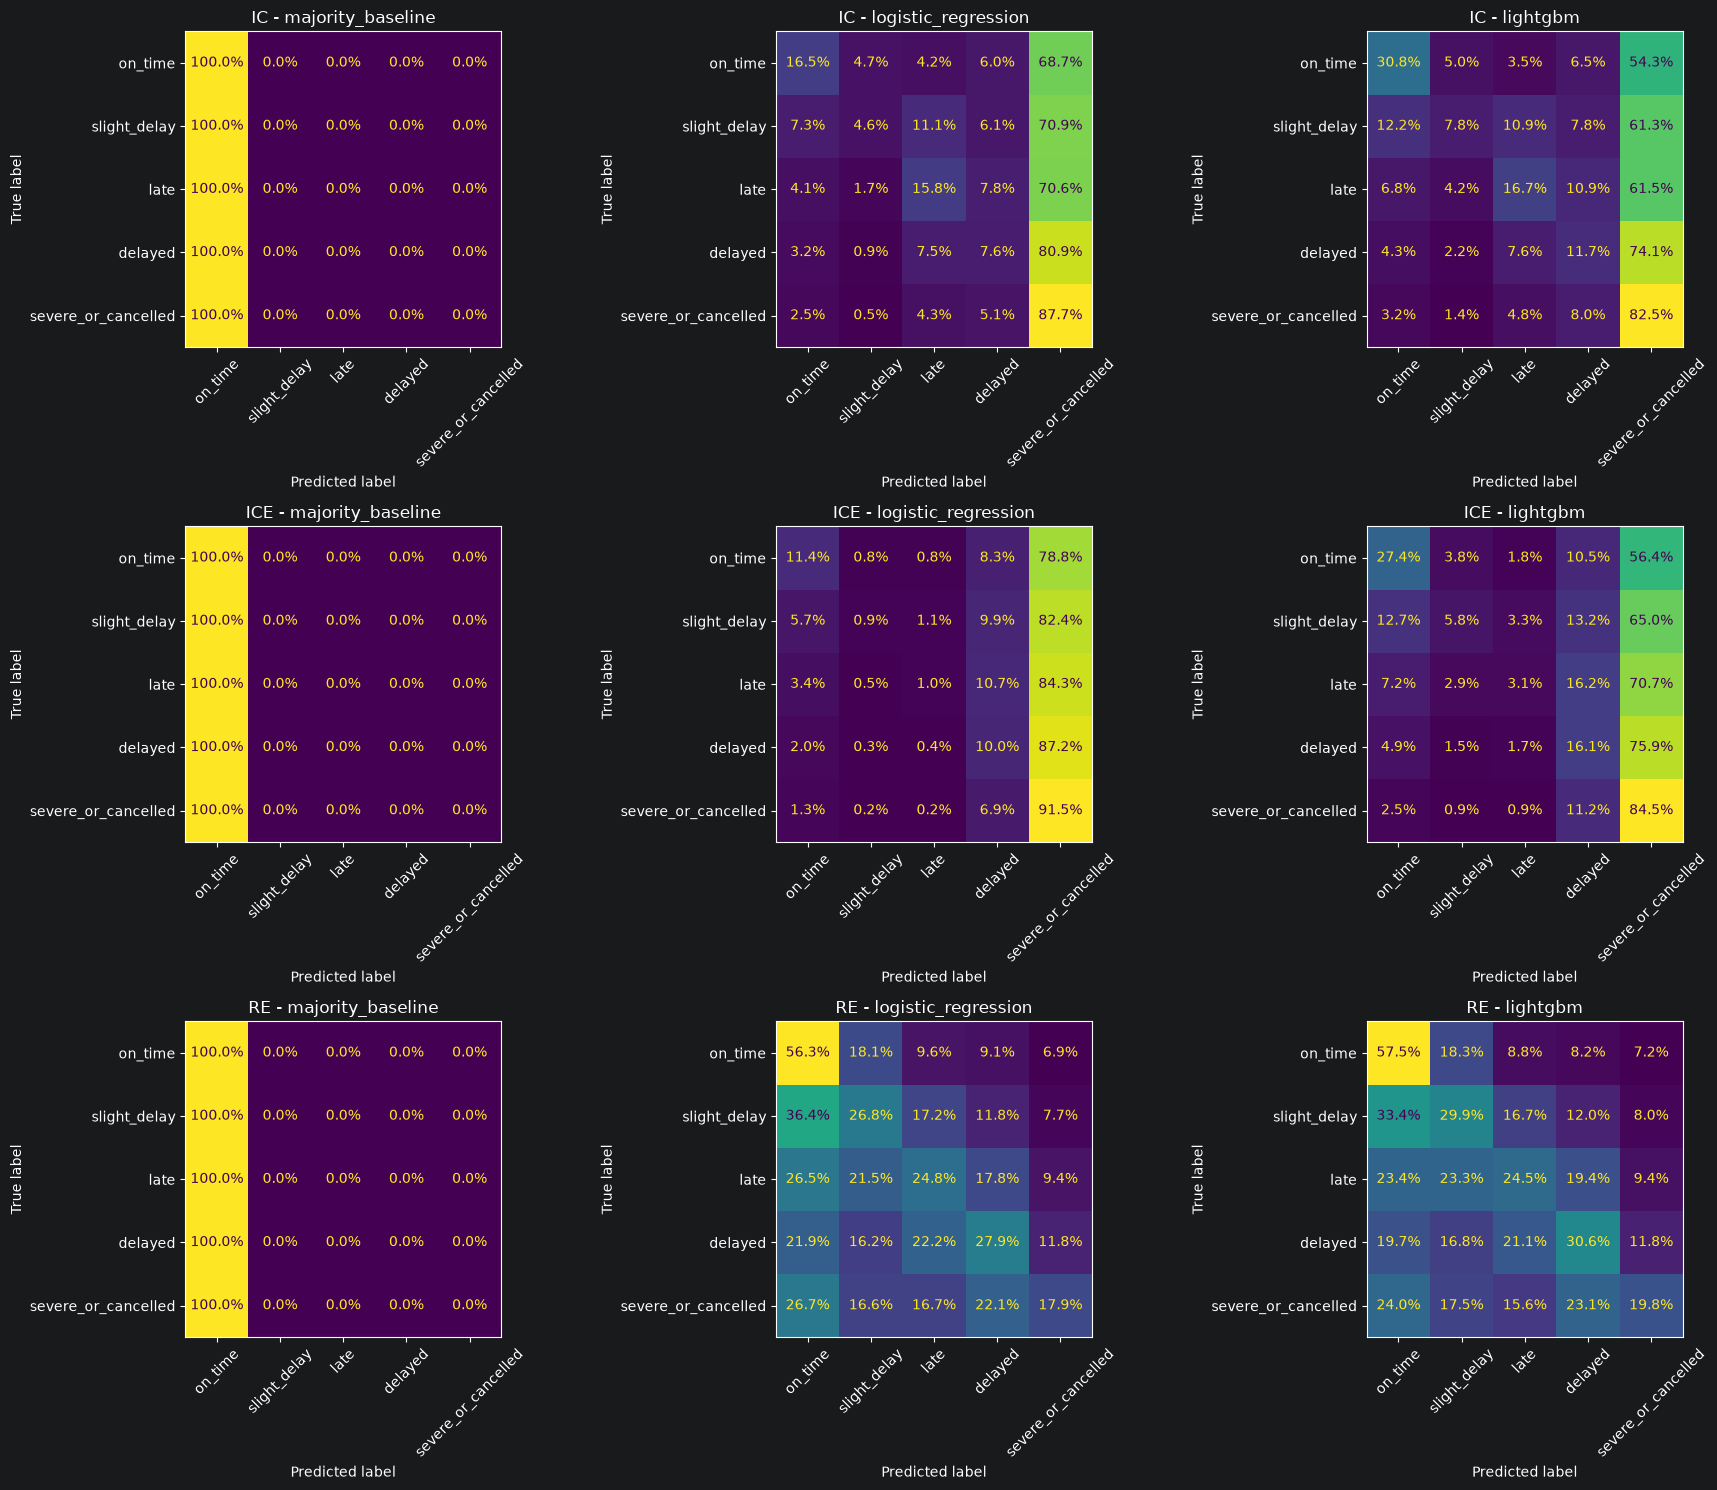

In [13]:
confusion_matrix_labels = [
    "on_time",
    "slight_delay",
    "late",
    "delayed",
    "severe_or_cancelled",
]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, (name, predicted) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        linear_data.y_validation,
        predicted,
        labels=confusion_matrix_labels,
        ax=axis,
        xticks_rotation=45,
        colorbar=False,
    )
    axis.set_title(name)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, (name, predicted) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        linear_data.y_validation,
        predicted,
        labels=confusion_matrix_labels,
        normalize="true",
        values_format=".1%",
        ax=axis,
        xticks_rotation=45,
        colorbar=False,
    )
    axis.set_title(f"{name} (percent)")
plt.tight_layout()
plt.show()

validation_train_types = processed_data["validation"]["train_type"].to_numpy()
train_types = ["IC", "ICE", "RE"]
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
for row, train_type in enumerate(train_types):
    row_mask = validation_train_types == train_type
    for column, (name, predicted) in enumerate(predictions.items()):
        ConfusionMatrixDisplay.from_predictions(
            linear_data.y_validation.to_numpy()[row_mask],
            np.asarray(predicted)[row_mask],
            labels=confusion_matrix_labels,
            normalize="true",
            values_format=".1%",
            ax=axes[row, column],
            xticks_rotation=45,
            colorbar=False,
        )
        axes[row, column].set_title(f"{train_type} - {name}")
plt.tight_layout()
plt.show()

## Conclusion

The models are compared using validation macro-F1 as the primary metric because the majority-class baseline can achieve reasonable accuracy without recognizing the minority classes. The majority baseline reaches 0.4354 accuracy but only 0.1213 macro-F1, since it predicts `on_time` for every row and has zero recall for the other four classes. Logistic regression improves macro-F1 substantially to 0.3093 and identifies all five classes, although its accuracy is lower at 0.3753. LightGBM is the best model overall: it reaches the highest validation macro-F1 of 0.3265 and an accuracy of 0.3944. Its advantage comes from better nonlinear handling of categorical, temporal, and interaction effects, leading to stronger performance across the delay classes rather than simply favoring the largest class. The confusion matrices also reveal an important limitation: fitting one model to all three train types may be a weakness. IC and ICE show a strong prediction bias toward `severe_or_cancelled`, while RE has a stronger tendency toward `on_time`; this suggests that train types have different class distributions and relationships that a single shared model does not capture equally well. The five-class target may also be too fine-grained, because neighboring delay categories are difficult to distinguish. A three-class target could be a more appropriate alternative for future work. The selected model should be evaluated once on the untouched chronological test partition only after the comparison and error analysis are complete.

## Final LightGBM test evaluation

LightGBM was selected using validation macro-F1. This one-time evaluation uses the untouched chronological test partition and does not change the fitted model.

In [18]:
lightgbm_test_predictions = np.asarray(target_names)[
    lightgbm_model.predict(X_test_boosted).astype(int)
]
lightgbm_test_result = macro_f1_test(
    lightgbm_model,
    X_test_boosted,
    linear_data.y_test,
    model_name="lightgbm",
    predictions=lightgbm_test_predictions,
)
pd.DataFrame([lightgbm_test_result])

,model,n_test,macro_f1,accuracy
0,lightgbm,2126112,0.322833,0.396198
